<h2> Infrastructure </h2>

In [ ]:
# Thermal Controller Board Level Prototype - By Shawn Newman

In [41]:
# Tips:  
  
# VSCode:
#    * Outline button is in the row of buttons right above this. Much easier navigation.
#    * Click on the blue bar to the left of a cell to hide it. Also works on outputs
#
# Jupyter Notebook:
#    * [View->Table of contents] for the outline
#    * You can click the arrow to the left of headings to collapse/expand their section
#
# Structure:
#    * The first code cell should run all the cells that simply define/import things
#    * The headings in the outline with an asterisk are the ones that actually use those functions, 
#      constants, and libraries to do things. You'll manually run those.
#    * Don't click the little "init" buttons in the bottom left of cells, it erases the tag
#
# Misc:
#    * [ctrl+Enter] runs a cell
#    * Select multiple lines of code, then press [ctrl+/] to comment or uncomment all 
#      (I just discovered this a couple months ago and am mad about it)

<h3>* Initialize All Functions and Libraries</h3>

In [1]:
# Turn on File->'Auto Save' if you want to use this. Reads cell data from disk.
# This runs every cell in here with the tag "init". Library imports, function definitions, constants, etc.
# Saves a lot of time

import nbformat # Library for manipulating notebooks

def execute_cells_by_tag(group_tag, quiet=True):
    filepath = globals()['__vsc_ipynb_file__'] # Returns path to this file
    if (quiet==False): print(filepath)
    nb = nbformat.read(open(filepath, 'r', encoding='utf-8'), as_version=4) # Saves this notebook as JSON
    ip = get_ipython()                                                      # Gets the "global InteractiveShell instance"
    if (quiet==False): print(ip)
    for cell_number in range(len(nb.cells)):
        cell=nb.cells[cell_number]
        #print(cell)
        if 'tags' in cell.metadata:
            if group_tag in cell.metadata.tags:
                ip.run_cell(cell.source)
                if (quiet==False): print(f"Ran Cell {cell_number}")

execute_cells_by_tag('init')

Imported Libraries
ICASL is loaded!
Initialized Constants:
Initialized Equipment's Establish Connection
Initialized Equipment Functions
Initialized Plotting Default Styling
Initialized Plotting Functions
Initialized Full Procedure


<h3> Import Libraries </h3>

In [2]:
import pyvisa                            # Instrument communication
import time                              # Handle time-related tasks (e.g., delays)
import matplotlib.pyplot as plt          # Plotting graphs and visualizing data
from matplotlib.ticker import LogLocator # Used for ticks in logarithmic plots
import numpy as np                       # Numerical operations, particularly with arrays
import pandas as pd                      # Data manipulation and analysis
import os                                # Interact with the operating system, such as handling file paths
import importlib.util                    # Used to load python files more dynamically

print("Imported Libraries")

Imported Libraries


In [44]:
# import ICASL.py
# print("Imported ICASL from this directory")
# ICASL.test()

In [3]:
# Loads ICASL.py from a higher directory
quiet=True
current_dir = "."
target_file = "ICASL.py"
target_name = "ICASL"
while True:
    if not quiet: print(current_dir)
    # Check if ICASL is in the current directory
    ICASL_path = os.path.join(current_dir, target_file)
    if not quiet: print(ICASL_path)
    if os.path.isfile(ICASL_path):
        # Loads ICASL.py
        spec = importlib.util.spec_from_file_location(target_name, ICASL_path)
        ICASL = importlib.util.module_from_spec(spec)
        spec.loader.exec_module(ICASL)
        break
    else:
        # Move one level up
        parent_dir = os.path.join(current_dir, "..")
        if not quiet: print(parent_dir)
        if current_dir == parent_dir:  # Reached the root directory
            raise ValueError("ICASL.py not found")
        else:
            current_dir = parent_dir
ICASL.test()

ICASL is loaded!


<h3> * Constants </h3>

In [105]:
DEVICE_NAME = "Prototype_Board" # GLOBAL directory
SET_PRECISION = .2  # How close the probe's temperature needs to get to the SET value before soak time begins (in Celsius)
SETTLING_TIME = .15 # Default wait time between setting values and measuring
# Required SETTLING_TIME will vary depending on the circuit. If there's a lot of sweeps, it can make the tests take much longer.
SOAK_TIME = 420  # How long to soak at temperature (in seconds). Blalock recommended 5 minutes. Longer now because how essential thermal precision is.
LOG = False

print("Initialized Constants:")

RUN_TIME = 60
MEASURE_TIME = 0.1

VSET_DEFAULT = -1.776

GLOBAL_TEMPS = [125, 100, 75, 50, 25,  0, -10, -20, -25, -28, -30, -35, -40, -50, -75, -100]

Initialized Constants:


<h2> Equipment </h2>

In [5]:
# Enable full pyvisa logging
pyvisa.log_to_screen()

In [6]:
# Disable full pyvisa logging
import logging
pyvisa.log_to_screen(level=logging.INFO)

In [12]:
# TODO: ADD POWER SUPPLIES TO TESTING CODE (need physical connections first)

def establish_connection(address, query):
    instrument = rm.open_resource(address)   # Open a connection to the instrument with the address and assign it to SM_VIN
    instrument.read_termination = '\n'       # Set the read termination character to a newline. This tells pyvisa when to consider a message as complete when reading from the instrument.
    instrument.write_termination = '\n'      # Set the write termination character to a newline. This ensures that each command sent to the instrument is properly terminated.
    instrument.baud_rate = 9600              # Set the baud rate for serial communication to 9600. This is the speed at which data is transmitted over the serial connection.
    print(instrument)                        # Print the resource object to display its properties
    if query != "NONE":
        print(instrument.query(query))           # Send the query to the instrument and print its response. This command usually asks the instrument to identify itself (e.g., manufacturer, model number).
    return instrument

print("Initialized Equipment's Establish Connection")

Initialized Equipment's Establish Connection


<h3>* Connect Equipment </h3>

In [ ]:
# Corresponding voltages/currents are in the names of equipment
# For a device with multiple channels, list each channel's voltage/current in order
# Everything except the temp chamber needs to be powered on beforehand.
rm = pyvisa.ResourceManager() 
MM_VRTD = establish_connection('USB0::10893::769::MY57508173::0::INSTR', '*IDN?')
MM_V1mA = establish_connection('USB0::10893::257::MY57508183::0::INSTR', '*IDN?')
#WG_VSET = establish_connection('GPIB6::10::INSTR', '*IDN?')
CHAMBER = establish_connection('GPIB6::6::INSTR', 'STATUS?')
OSC_oscillator = establish_connection('USB0::2391::6070::MY56310504::INSTR', '*IDN?')
OSC_tri_pulse = establish_connection('', '*IDN?')


USBInstrument at USB0::10893::769::MY57508173::0::INSTR
Keysight Technologies,34465A,MY57508173,A.02.17-02.40-02.17-00.52-04-01
USBInstrument at USB0::10893::257::MY57508183::0::INSTR
Keysight Technologies,34465A,MY57508183,A.02.17-02.40-02.17-00.52-04-01
GPIBInstrument at GPIB6::6::INSTR
YNNNYYYYNNNNNNNNNN0
USBInstrument at USB0::2391::6070::MY56310504::0::INSTR
AGILENT TECHNOLOGIES,MSO-X 4024A,MY56310504,04.08.2016071800


Equipment Info

In [ ]:
# To find IDs

# Waveform Generators: System -> I/O Settings -> USB
# Multimeters:
# SourceMeters:
# Sun Chamber: 'GPIB6::6::INSTR'

# Temperature Chamber Status Code

# Y = power is on
# 2: Y = command error last command
# 3: Y = time out LED is on
# 4: Y = waiting for timeout
# 5: Y = heat output is enabled
# 6: Y = cool output is enabled
# 7: Y = valid set temperature
# 8: Y = deviation limit exceeded
# 9: Y = currently ramping
# 10: Y = chamber temp < lower limit
# 11: Y = chamber temp > upper limit
# 12: Y = waiting at a BKPNT
# 13: Y = in LP run mode
# 14: Y = in LP remote store mode
# 15: Y = in local edit LP mode
# 16: Y = waiting to run LP at TOD
# 17: Y = GPIB bus timeout
# 18: Y = in local keyboard lockout mode
# 19: 0 = system Self Test was OK
# 1 = Battery RAM error found (check default settings)
# 2 = EE RAM error found (check probe calibration)
# 3 = ROM error found (call factory)

<h3> Equipment Functions </h3>

In [128]:
####### Temperature Chamber #######

def chamber_init():
    CHAMBER.write("ON")                  # Also turns on heat and cool (unless configured otherwise)
    CHAMBER.write("RATE={CHAMBER_RATE}") # Sets the speed at which the chamber will ramp to change temp
    CHAMBER.write("WAIT=FOREV")          # Sets the time that the chamber will wait once the desired temperature is reached before moving to next temp. We don't use this.
    CHAMBER.write("HON")                 # Turns heat on (just in case)
    CHAMBER.write("CON")                 # Turns cool on (just in case)
    CHAMBER.write("PIDA=3")              # Switches to monitoring user probe when setting temperature (DUT will reach temperature, not the top of the chamber)
    time.sleep(1) 
    #print(CHAMBER.query("RATE?"))
    #print(CHAMBER.query("WAIT?"))

# TODO: Figure out when SCPI needs leading colons (never?)
# TODO: Switch to using full names for SCPI commands

# Initializations

####### MM #######

def MM_init(MM):
    MM.write(":CONF:VOLT:DC")
    MM.write("VOLT:DC:RANG 10")
    MM.write("VOLT:NPLC 10")

# TODO Oscilloscope init?

# TODO: MM_reset() ?

####### WG #######

def WG_init(WG):
    WG.write("OUTP1:LOAD DEF")          # Sets the output load to infinite so no impedance matching is necessary
    WG.write("SOUR1:APPL:DC")          # Sets the Waveform generator to output a DC voltage

def WG_on(WG, channel, val):
    # Only channel 1 was used for this test, for VSET
    # We had a second, separate waveform generator output a triangle wave, manually set.
    # A third waveform generator applied a reference signal to the oscilloscope.
    if (channel != 1 and channel != 2):
        print("Invalid channel")
        return -1
    WG.write(f"SOUR{channel}:APPL:DC DEF, DEF, {val}")
    WG.write(f"OUTP{channel}:STAT 1")

def WG_off(WG, channel):
    if (channel != 1 and channel != 2):
        print("Invalid channel")
        return -1
    WG.write(f"SOUR{channel}:APPL:DC DEF, DEF, 0")
    WG.write(f"OUTP{channel}:STAT 0")

def OSC_measure_freq(OSC, channel):
    OSC.write(":MEASure:CLEar")
    return OSC.query(f":MEASURE:COUNTER? CHANNEL{channel}")

def OSC_measure_duty(OSC, channel):
    #OSC.write(":MEASure:CLEar")
    return OSC.query(f":MEASURE:DUTY? CHANNEL{channel}")

def OSC_measure_peak_to_peak(OSC, channel):
    #OSC.write(":MEASure:CLEar")
    return OSC.query(f":MEASURE:VPP? CHANNEL{channel}")

def OSC_measure_std(OSC, channel):
    return OSC.query(f":MEASURE:SDEVIATION? CHANNEL{channel}")

def OSC_set_measurements(OSC, channel):
    OSC.write(f":MEASURE:COUNTER CHANNEL{channel}")
    OSC.write(f":MEASURE:FREQUENCY CHANNEL{channel}")
    OSC.write(f":MEASURE:VPP CHANNEL{channel}")
    OSC.write(f":MEASURE:DUTY CHANNEL{channel}")
    OSC.write(":MEASURE:STATISTICS")
    OSC.write(":MEASURE:STATISTICS:DISPLAY 1")

####### Groupings #######
# Do not affect temperature chamber

def initialize_all():
    MM_init(MM_VRTD)
    MM_init(MM_V1mA)
    # TODO: Oscilloscope init?
    #WG_init(WG_VSET)

def turn_on_all():
    time.sleep(1) 
    #WG_on(WG_VSET, 1, VSET_DEFAULT)

def turn_off_all():
    #WG_off(WG_VSET, 1)  # Turn off VREF
    pass

def measure_all():
    # Will not work if trigger link is initialized, so:
    MM_VRTD.query(":READ?")
    MM_V1mA.query(":READ?")

def measure_all_continuously(time_between):
    try:
        while(True):
            time.sleep(time_between)
            MM_VRTD.query(":READ?")
            MM_V1mA.query(":READ?")
    except KeyboardInterrupt:
        pass

print("Initialized Equipment Functions")

Initialized Equipment Functions


<h3>* Test Equipment </h3>

In [108]:
# Test Multimeters
MM_init(MM_VRTD)
print(MM_VRTD.query(":CONF?"))
print(MM_VRTD.query(":READ?"))

MM_init(MM_V1mA)
print(MM_V1mA.query(":CONF?"))
print(MM_V1mA.query(":READ?"))

"VOLT +1.00000000E+01,+1.00000000E-06"
+6.53829276E-01
"VOLT +1.00000000E+01,+1.00000000E-06"
+2.00123582E+00


In [ ]:
# Test Waveform Generators

WG_init(WG_VSET)
WG_on(WG_VSET, 1, VSET_DEFAULT)

In [112]:
OSC_set_measurements(OSC_oscillator, 1)

In [124]:
OSC_measure_freq(OSC_oscillator, 1)

'+99E+36'

In [139]:
print(OSC_measure_duty(OSC_oscillator, 1))
print(OSC_measure_peak_to_peak(OSC_oscillator, 1))
print(OSC_measure_std(OSC_oscillator, 1))

+41.8E+00
+1.22745E+00
+434.155E-03


In [ ]:
#turn_on_all()

In [18]:
measure_all()

In [ ]:
turn_off_all()

<h2> Plotting </h2>

In [117]:
# ICASL.start_plot() defines global default plotting parameters. Has a couple styles built in.
# local_start_plot() defines default plotting parameters for this specific file. So if you want to change something about all of these
# plots, you could either add code before the call to ICASL or eliminate the call to ICASL and write your own function entirely.
# These are essentially middle managers
def local_start_plot(title, xlabel, ylabel):
    fig, ax = ICASL.start_plot(title, xlabel, ylabel)
    return fig, ax

def local_finish_plot(fig, ax, save_dir="none", save_file="none", cm=plt.get_cmap('gist_rainbow'), legend=None, legend_style="#", annotations=None, close=True, show=False):
    # legend = ax.legend(bbox_to_anchor=(1.02, 1))
    # legend_style = "b"
    ICASL.finish_plot(fig, ax, save_dir=save_dir, cm=cm, save_file=save_file, legend=legend, legend_style=legend_style, annotations=annotations, close=close, show=show)

print("Initialized Plotting Default Styling")

Initialized Plotting Default Styling


<h3> Plotting Functions </h3>

In [118]:
################## Initialize and format plots ##################

def PI_control_plot_VRTD_init(title, x_label, y_label):
    fig, ax = local_start_plot(title, x_label, y_label)
    #ax.set_xticks(ICASL.arange(VDD_MIN, VDD_MAX, 0.2))
    #ax.set_xlim(VDD_MIN, VDD_MAX)
    return fig, ax

def PI_control_plot_VRTD(read_dir, write_dir, amb_T, VSET):
    df = ICASL.read_csv(os.path.join(read_dir, f"amb_T={amb_T}", f"VSET={VSET}", f"PI_control.csv"))
    df = ICASL.fix_dataframe(df)

    fig, ax = PI_control_plot_VRTD_init(f"PI Control with ambient={amb_T}°C and VSET={VSET} V", "Time (s)", f"RTD Voltage (V)")
    ax.plot(df["time"], df["VRTD"], label=f"VSET={VSET} V")
    local_finish_plot(fig, ax, write_dir, f"amb_T={amb_T}_VSET={VSET}_PI_control_VRTD.png")

def PI_control_plot_freq_init(title, x_label, y_label):
    fig, ax = local_start_plot(title, x_label, y_label)
    #ax.set_xticks(ICASL.arange(VDD_MIN, VDD_MAX, 0.2))
    #ax.set_xlim(VDD_MIN, VDD_MAX)
    return fig, ax

def PI_control_plot_freq(read_dir, write_dir, amb_T, VSET):
    df = ICASL.read_csv(os.path.join(read_dir, f"amb_T={amb_T}", f"VSET={VSET}", f"PI_control.csv"))
    df = ICASL.fix_dataframe(df)

    fig, ax = PI_control_plot_freq_init(f"PI Control with ambient={amb_T}°C and VSET={VSET} V", "Time (s)", f"Frequency (Hz)")
    ax.plot(df["time"], df["freq"], label=f"VSET={VSET} V")
    local_finish_plot(fig, ax, write_dir, f"amb_T={amb_T}_VSET={VSET}_PI_control_freq.png")

def PI_control_plots(read_dir, write_dir, amb_Ts, VSETs):
    for amb_T in amb_Ts:
        for VSET in VSETs:
            PI_control_plot_VRTD(read_dir, write_dir, amb_T, VSET)
            PI_control_plot_freq(read_dir, write_dir, amb_T, VSET)

# ambs_Ts and VSETs should be lists, even if you only need one value (e.g. [25] for 25 degrees)
def plot_all(read_dir, write_dir, amb_Ts, VSETs):
    PI_control_plots(read_dir, write_dir, amb_Ts, VSETs)

print("Initialized Plotting Functions")

Initialized Plotting Functions


<h3>* Preview Plot Formatting </h3>

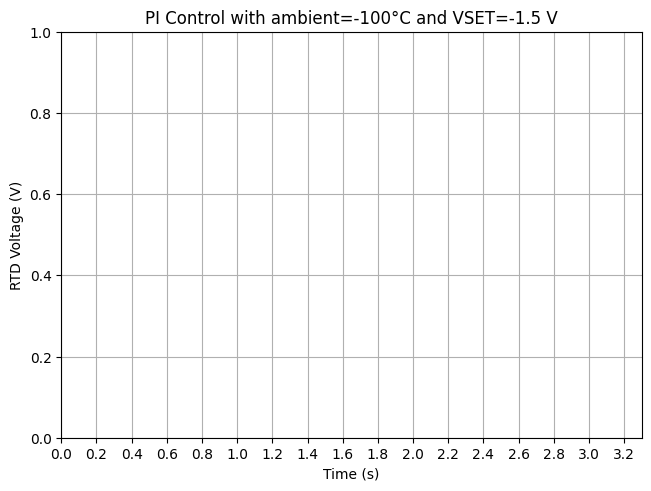

In [10]:
# Use this to print the formatting of all of your plots - not called during tests
# This is why plot initializations are separate

plot_amb_Ts = [-100]
plot_VSETs = [-1.5]

def initialize_all_plots(amb_Ts, VSETs):
    for amb_T in amb_Ts:
        for VSET in VSETs:
            fig, ax = PI_control_plot_init(f"PI Control with ambient={amb_T}°C and VSET={VSET} V", "Time (s)", f"RTD Voltage (V)")
            pass # "pass" allows you to comment out the above line without python yelling at you for the loop doing nothing
    plt.show()

initialize_all_plots(plot_amb_Ts, plot_VSETs)

<h3>* Generate Experimental Plots </h3>

In [ ]:
# Manual use - Not called during procedure

plot_amb_Ts = [-100]
plot_VSETs = [-1.5]

date = "2026-06-29" # Manually set 
run = "Practice_Run_3_[-50°C][DUT 1]" # Manually set
read_dir = os.path.join(f"{DEVICE_NAME}_Results", date, run) 
write_dir = os.path.join(f"{DEVICE_NAME}_Results", date, run, "Plots_Generated_Later") # Make sure this doesn't overwrite anything important

# dir = os.path.join("Combined_Data", "Combined_Experiment")
# read_dir = os.path.join(dir, "Combined_Temps")
# write_dir = os.path.join(dir, "Plots")
# os.makedirs(write_dir,exist_ok=True)

LOG = True
PI_control_plots(read_dir, write_dir, plot_amb_Ts, plot_VSETs)

[-50]


<h2> Running Experiment </h2>

<h3> Test Functions </h3>

In [126]:
# Tests/Sweeps:

def run_tests(save_dir):
    # Comment out tests you don't want to run
    # Make sure to also comment out corresponding plotting functions in plot_all() !!!
    PI_control(save_dir)


def PI_control(save_dir):
    time.sleep(1)
    VRTDs = []
    V1mAs = []
    freqs = []
    times = []
    current_time = 0

    # TODO: Set VSET?

    while (current_time >= RUN_TIME):
        VRTDs.append(MM_VRTD.query(":READ?"))
        V1mAs.append(MM_V1mA.query(":READ?"))
        freqs.append(OSC_measure_freq(OSC_oscillator, 1))
        # OSC_set_measurements(OSC_oscillator, 1) # Reset visually
        times.append(current_time)
        time.sleep(MEASURE_TIME)
        current_time += MEASURE_TIME
        # if (current_time >= MEASURE_TIME*10):
        #     print(f"Setting VSET to {VSET_DEFAULT} at time {current_time}")
        #     WG_on(WG_VSET, 1, VSET_DEFAULT)

    if LOG: print(f"Finished running for time {RUN_TIME}, storing")

    # Store data
    df = pd.DataFrame({'time': times, 'VRTD': VRTDs, 'VRTD': VRTDs, 'frequency' : freqs})  # Create a DataFrame
    df.to_csv(os.path.join(save_dir, f'PI_Control_Data.csv'), index=False)

<h3> Temperature Sweep </h3>

In [120]:
#####################################################################################################################
################## IMPORTANT: Make sure all CHAMBER commands are contained with an if(USE_CHAMBER): #################
#####################################################################################################################

# USE_CHAMBER = True - turns on the temperature chamber and performs the temperature sweep
# USE_CHAMBER = False - performs a test run without interacting with the chamber.

def temperature_sweep(USE_CHAMBER, run_dir, local_temps=GLOBAL_TEMPS, additional_temps_to_plot=[], do_cold_start=False):
    
    ################## Temperature Sweep ##################
         
    # This allows you to plot temperatures tested in previous runs. Make sure you're using the same "run_dir". 
    temps_tested = additional_temps_to_plot 

    for temp in local_temps:
        temp_dir = os.path.join(run_dir, f"temp={temp}") # The temperature of the experiment gets set as the sub-directory name
        os.makedirs(temp_dir, exist_ok=True) # Create a directory with the given name. If the directory already exists, it won't raise an error due to exist_ok=True

        if (USE_CHAMBER): 
            user_probe_temp = float(CHAMBER.query("USER?"))
            while(True):
                if (temp < -165 and user_probe_temp < -155):
                    CHAMBER.write("RATE=10")     # Slow chamber's rate of change. Seems to result in less LN2 spillage.
                    CHAMBER.write("HOFF")        # Stops chamber from heating. One time it applied a little heat at -175 and rapidly dropped the DUT temp.
                time.sleep(10)
                measure_all() # Updates readings periodically during time between tests
                #print(CHAMBER.query("STATUS?"))
                user_probe_temp = CHAMBER.query("USER?")
                if (temp+SET_PRECISION >= float(user_probe_temp) >= temp-SET_PRECISION):
                    break
                # TODO: More advanced algorithm for settling.
            print(f"{temp}: {CHAMBER.query("STATUS?")}")
            time.sleep(SOAK_TIME)

        # Tests
        if LOG: print(f"Performing Tests at temp {temp}")
        run_tests(temp_dir)
        if LOG: print("Finished Tests")

        rename = ICASL.remove_attribute(run_dir, "No_Plots") # The directory containing this has the attribute "[No_Plots]" removed.
        # Assembles name of sub-directory
        if rename != None and isinstance(rename, str):
            run_dir = rename
            temp_dir = os.path.join(run_dir, f"temp={temp}") # The temperature of the experiment gets set as the sub-directory name
            time.sleep(3)
        temps_tested.append(temp)
        #plot_all(run_dir, temp_dir, temps_tested) # Intermediate plots. Runs each temperature, shows all so far. 
    
    # Overall plots
    FINAL_PLOTS_DIR = os.path.join(run_dir, "Final_Plots")
    os.makedirs(FINAL_PLOTS_DIR, exist_ok=True)
    plot_all(run_dir, FINAL_PLOTS_DIR, local_temps)

    if (USE_CHAMBER and do_cold_start):
        cold_start(temps_tested[-1], run_dir)

# For this particular test, the power supplies will not be turned off. You must do so manually.
def cold_start(temp, run_dir):
    turn_off_all()   # Turn off voltages
    time.sleep(900)  # Wait 15 minutes for device to cool down
    turn_on_all()

    # Cold start data is stored in a subdirectory. This means it is ignored by default but can be
    # parsed identically by simply passing the subdirectory to functions rather than the higher directory
    run_dir_CS = os.path.join(run_dir, "Cold_Start")
    temp_dir_CS = os.path.join(run_dir_CS, f"temp={temp}")
    os.makedirs(temp_dir_CS, exist_ok=True)
    
    run_tests(temp_dir_CS)   
    plot_all(run_dir_CS, temp_dir_CS, [temp])

    turn_off_all()
    # Temperature Chamber is NOT off at this point. Close valve, let the pipes empty, then set it back to room temp.


print("Initialized Full Procedure")

Initialized Full Procedure


<h3>* Inputs for Running Experiment</h3>

In [4]:
turn_on_all()

In [121]:
measure_all()

In [122]:
# DO NOT RUN WITH OUTPUT OFF
measure_all_continuously(time_between=.5)

In [17]:
# You'll need to run this every time you stop mid-test
turn_off_all()

#### Single Temperature Run

In [125]:
# PRACTICE Run, chamber not affected.
# Runs all of the "temperature sweep" code without actually touching the temperature. Good for running at a single temp.

# Inputs
practice_temperature = [-100] # Change this if you do a practice run at another temp. For file labeling purposes, doesn't actually set the temp.
info = f"First Test"
LOG = True
RUN_TIME = 60
MEASURE_TIME = 0.5

execute_cells_by_tag('init') 
# TODO: VSET OFF?
# TODO: Reset Equipment?
initialize_all()
LOG = True    # I'm using this to regulate log levels (whether debug print statements run) - not the best way
run_dir = ICASL.generate_experiment_name("Single_Temp", practice_temperature, DEVICE_NAME, info) # Create file path
if LOG: print(f"Run directory is {run_dir}")
temperature_sweep(False, run_dir, local_temps=practice_temperature)

Imported Libraries
ICASL is loaded!
Initialized Constants:
Initialized Equipment's Establish Connection
Initialized Equipment Functions
Initialized Plotting Default Styling
Initialized Plotting Functions
Initialized Full Procedure
Run directory is Prototype_Board_Results\2026-03-29\Single_Temp_1_[-100°C][No_Plots][First Test]
Performing Tests at temp -100


KeyboardInterrupt: 

#### Run across temperature

In [ ]:
# ACTUAL Run, chamber sweeps temperature

# Inputs
#local_temps = GLOBAL_TEMPS # Can change this to any list of temps. Ex: [0, 27, 50]. Runs in order.
local_temps = [] 
CHAMBER_RATE = 20

execute_cells_by_tag('init') 
# TODO: VSET OFF?
# TODO: Reset Equipment?
initialize_all()
LOG = False
print(local_temps)
run_dir = ICASL.generate_experiment_name("Experiment", local_temps, DEVICE_NAME) # Create file path

# CHAMBER IS USED # CHAMBER IS USED # CHAMBER IS USED
chamber_init()
temperature_sweep(USE_CHAMBER=True, run_dir=run_dir, local_temps=local_temps) 
# CHAMBER IS USED # CHAMBER IS USED # CHAMBER IS USED

Imported Libraries
ICASL is loaded!
Initialized Constants:
Trigger Count = 1801
Initialized Equipment's Establish Connection
Initialized Equipment Functions
Initialized Plotting Default Styling
Initialized Specific Plots
Initialized Full Procedure
[-175]
YNNNNYYYNNNNNNNNNN0


Continue Experiment

In [ ]:
# Run this cell for output that's close to what you need for temps_tested - might need to remove a temp that wasn't fully tested

sweep_variable_name = "temp"
old_dir = os.path.join("PTAT_Current_Reference_Results", "2025-07-17", "Experiment_2") # Copy/paste in the previous experiment's directory name
print(ICASL.read_dir_values(old_dir, sweep_variable_name))

temps_tested = [] # Enter existing temps to not test at, but still use during plotting

[-175, -150]


In [ ]:
# Continue an existing ACTUAL Run, chamber sweeps temperature
# If you have to stop an experiment midway, use this to pick up right where you left off.

#local_temps = GLOBAL_TEMPS
#local_temps = [temp for temp in GLOBAL_TEMPS if temp not in temps_tested]
local_temps = [-100, -125, -150, -175]
print(local_temps)


if (old_dir == "" or temps_tested == []): raise ValueError("Don't use this without an old_dir and temps_tested")
import shutil
execute_cells_by_tag('init') 
turn_off_all()
LOG = False
run_dir = ICASL.generate_experiment_name("Experiment", local_temps, DEVICE_NAME)

# Copies old_dir contents to run_dir
for item in os.listdir(old_dir):
    absolute_source_item = os.path.join(old_dir, item)
    relative_source_item = os.path.basename(absolute_source_item)
    num = ICASL.parse_num_from_string(relative_source_item, sweep_variable_name)
    if (num != None and num not in temps_tested):
        # Don't copy over temp folders that weren't mentioned in temps_tested
        continue
    else:
        destination_item = os.path.join(run_dir, item)
        if os.path.isdir(absolute_source_item): 
            shutil.copytree(absolute_source_item, destination_item, dirs_exist_ok=True)
        else:
            shutil.copy2(absolute_source_item, destination_item)

# CHAMBER IS USED # CHAMBER IS USED # CHAMBER IS USED # CHAMBER IS USED # CHAMBER IS USED
temperature_sweep(True, run_dir, local_temps=local_temps, additional_temps_to_plot=temps_tested) # CHAMBER IS USED
# CHAMBER IS USED # CHAMBER IS USED # CHAMBER IS USED# CHAMBER IS USED# CHAMBER IS USED

Imported Libraries
ICASL is loaded!
Initialized Constants:
Trigger Count = 1801
Initialized Equipment's Establish Connection
Initialized Equipment Functions
Initialized Plotting Default Styling
Initialized Specific Plots
Initialized Full Procedure
[-100, -125, -150, -175]
YNNNYYYNNNNNNNNNNN0
YNNNYYYYNNNNNNNNNN0


KeyboardInterrupt: 

Return Chamber to Room Temperature

In [6]:
# Return to room temperature
# TURN VALVE AND WAIT FIRST
CHAMBER.write("HON")
CHAMBER.write("COFF")
CHAMBER.write("RATE=20")
CHAMBER.write("SET=25")

7